# No Evesdropping BB84 QBER

This notebook reproduces the results of []() and recreates Figure 1 of it. Note that in this simulation there is no evesdropper. For each channel the sweep is between $p=0,0.02,\ldots,0.20$ and there are $1000$ signals sent per fun. The QBER is averaged accross five different runs. The identity line is given by $Q=p$, and the Shor-Priskill bound is given at $\sim 11\%$.

In [1]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np

from modules import BB84, Depolarizing, AmplitudeDamping, PhaseFlip

## Channel parameters

Note that in each channel the probability parameter represents something different:
- In `Depolarizing`, `p` represents the total probability of a nonidentity Pauli error.
- In `AmplitudeDamping`, `p` represents the excited-state decay probability.
- For phase damping using the `PhaseFlip(q)` with parameter `q` where $q=(1-\sqrt{1-p})/2$. This makes the off-diagonal coherence shrink by $\sqrt{1-p}$.

For a single channel on the signal and uniform BB84 inputs, the expected QBERs are

$$Q_{\mathrm{depol}}=\frac{2p}{3},\qquad
Q_{\mathrm{phase}}=\frac{1-\sqrt{1-p}}{4},\qquad
Q_{\mathrm{amp}}=\frac{p+1-\sqrt{1-p}}{4}.$$

The graph uses simulated QBER values, rather than these formulas. The ordering can differ from the paper because this experiment applies noise once during transmission.

## Run the noise sweep

In [2]:
number_bits = 1000
repeats = 5
seed = 0

probabilities = np.arange(11) / 50
channels = {
    "Depolarizing noise": Depolarizing,
    "Phase damping noise": lambda p: PhaseFlip((1 - np.sqrt(1 - p)) / 2), # makes off diagonal coherence shrink by sqrt(1-p)
    "Amplitude damping noise": AmplitudeDamping,
}

seeds = iter(np.random.SeedSequence(seed).spawn(3 * len(probabilities) * repeats)) # randomize seed
runs = []
averages = {}

In [3]:
for name, channel_type in channels.items():
    means = []
    for p in probabilities:
        qbers = []
        for trial in range(repeats):
            run_seed = int(next(seeds).generate_state(1, dtype=np.uint64)[0]) # change seed by set amount 
            bb = BB84(seed=run_seed, number_bits=number_bits)
            bb.key_generation(signal_channel=channel_type(p), record_rounds=())
            qbers.append(bb.qber())
            runs.append({"channel": name, 
                         "noise_probability": float(p),
                         "trial": trial, 
                         "seed": run_seed,
                         "transmitted": number_bits, 
                         "sifted": len(bb.alice_key),
                         "errors": int(np.count_nonzero(bb.alice_key != bb.bob_key)),
                         "qber": bb.qber(), 
                         "loss_rate": bb.loss_rate()
                        })
        means.append(float(np.mean(qbers)))
    averages[name] = np.array(means)

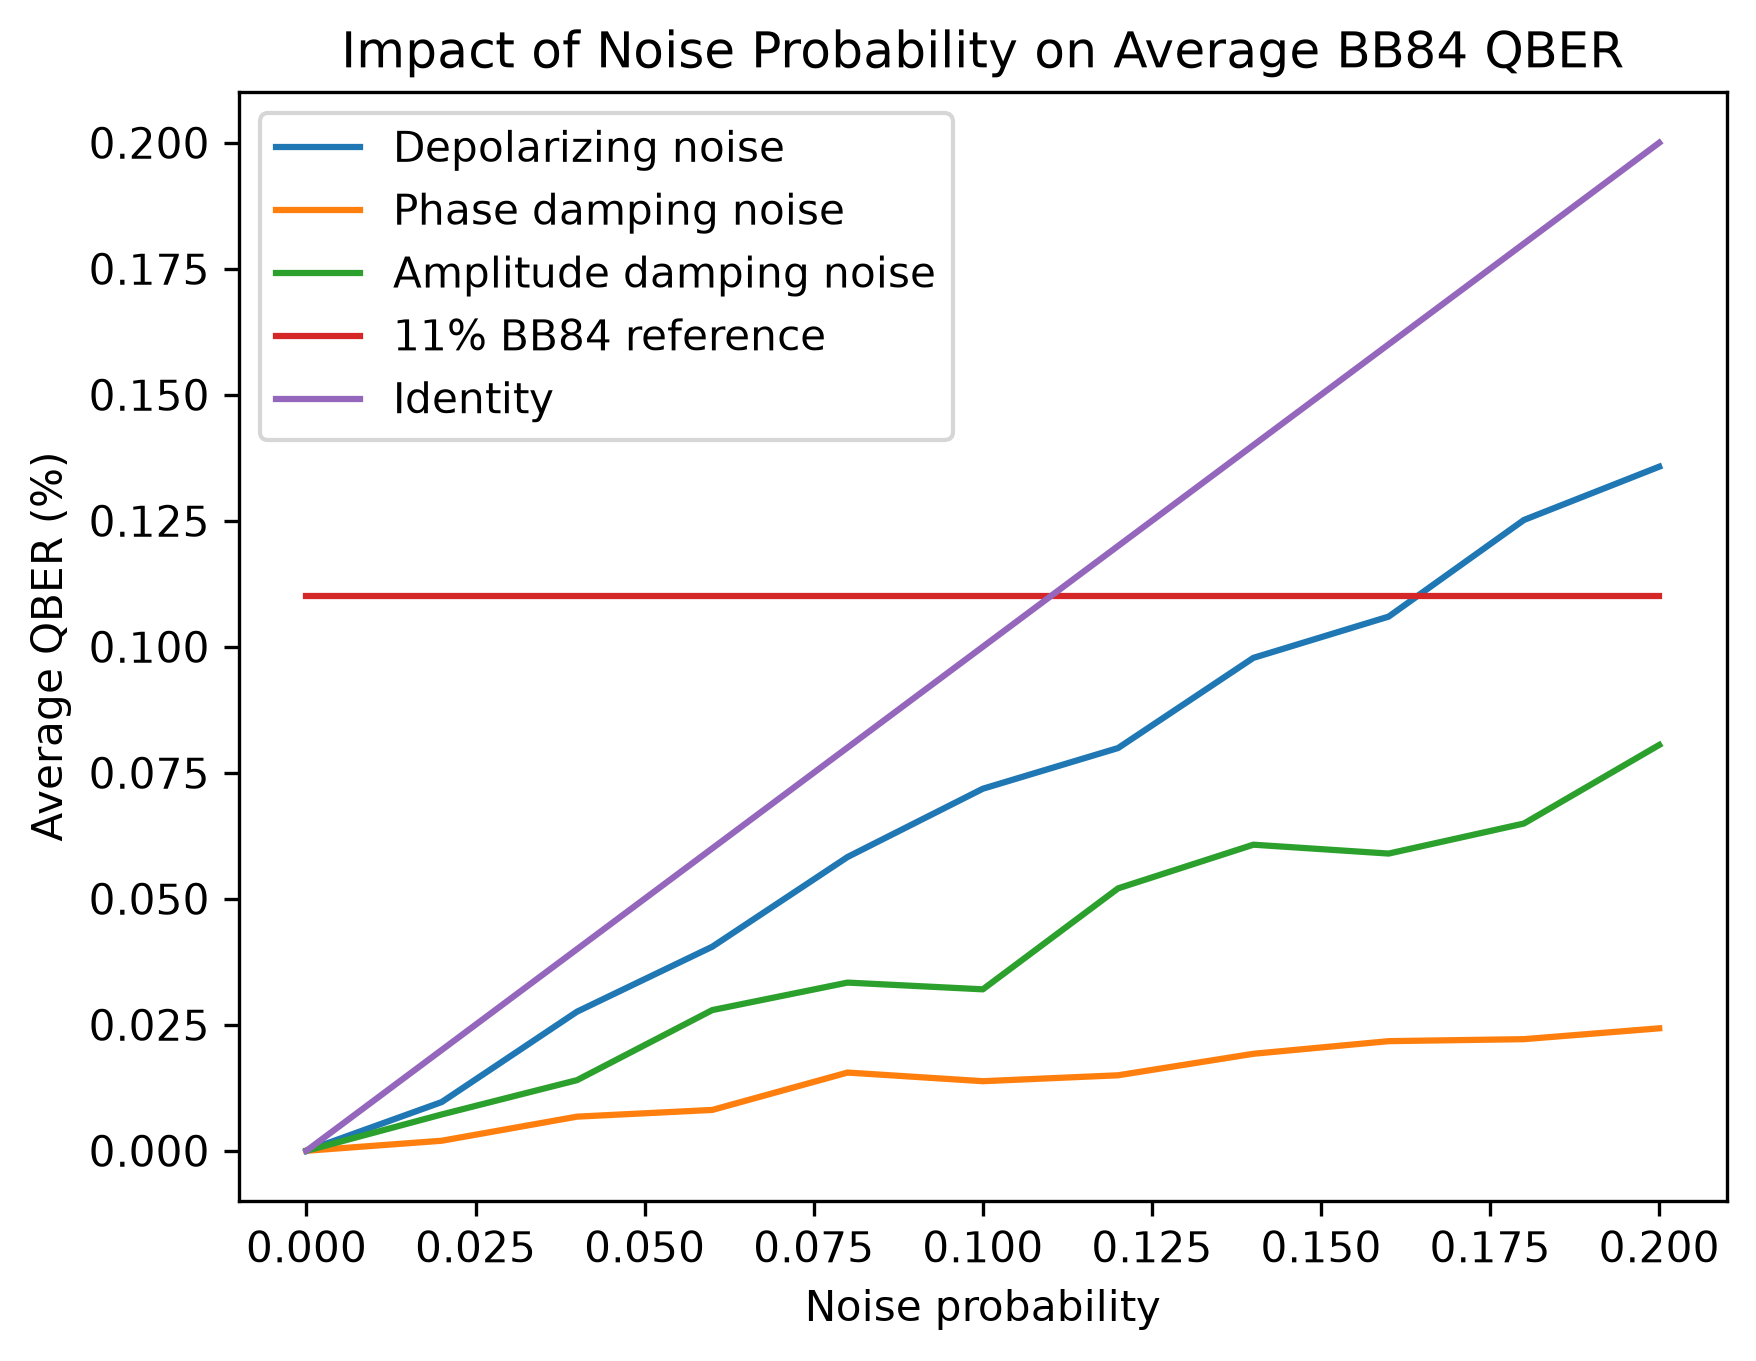

In [4]:
fig, ax = plt.subplots(dpi=300)

for name, values in averages.items():
    ax.plot(probabilities, values, label=name)

ax.plot(probabilities, np.full(len(probabilities), 0.11), label="11% BB84 reference")
ax.plot(probabilities, probabilities, label="Identity")

ax.set_title("Impact of Noise Probability on Average BB84 QBER")
ax.set_xlabel("Noise probability")
ax.set_ylabel("Average QBER (%)")
ax.legend()

plt.show()

In [5]:
output = Path("../data")

output.mkdir(parents=True, exist_ok=True)

fig.savefig(output / "bb84_noise_sweep_qber.png", dpi=200, bbox_inches="tight")

with (output / "bb84_noise_sweep_runs.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(runs[0]))
    writer.writeheader()
    writer.writerows(runs)

with (output / "bb84_noise_sweep_average_qber.csv").open("w", newline="") as stream:
    writer = csv.writer(stream)
    writer.writerow(["noise_probability", *averages])
    writer.writerows(zip(probabilities, *averages.values()))